# 06 - Budget-aware CRM campaign scenarios

A high probability of no purchase does not imply that a discount will change behaviour. This notebook uses modelled baseline purchase probability plus an **assumed** absolute response uplift. Margin, coupon cost, contact cost and budget are explicit inputs. All incremental profits below are scenario estimates, not observed campaign results.

Run `scripts/run_pipeline.py` first. This notebook recomputes audience selection and sensitivity from its latest scored household table; it does not re-train a second, inconsistent model.

**Scope:** every selected household receives the same hypothetical USD 2 offer. No COUPON_UPC, product/category choice or personalised coupon assignment is produced. The purchase prediction reflects historical promotion conditions; treating it as a no-new-offer probability is an additional scenario assumption.

**Step 1: Prepare imports, imports, imports.**

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

plt.ioff()
from IPython.display import display, Markdown

ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src/retail_customer_360/metrics.py").is_file()
    ),
    None,
)


**Step 2: Prepare config, FIGURES.**

In [2]:
if ROOT is None:
    raise RuntimeError("Open inside retail-customer-360")
sys.path.insert(0, str(ROOT / "src"))
config = json.loads((ROOT / "config/project.json").read_text())
plt.style.use("seaborn-v0_8-whitegrid")
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)
BLUE, TEAL, ORANGE = "#245C83", "#208778", "#D77931"


**Step 3: Define the finish helper.**

In [3]:
from IPython.display import Image as NotebookImage


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight", facecolor="white")
    display(NotebookImage(filename=str(FIGURES / name)))
    plt.close(fig)


**Step 4: Check the calculation.**

In [4]:
import hashlib
from retail_customer_360.crm import (
    select_campaign,
    campaign_sensitivity,
    compare_policies,
)

OUT = ROOT / "data/processed/portfolio"
manifest = json.loads((OUT / "run_manifest.json").read_text())
assert manifest["config"] == config, "Configuration changed: rerun the pipeline first."


**Step 5: Load data and inspect the input.**

In [5]:
for filename, source in manifest["sources"].items():
    digest = hashlib.sha256()
    with (ROOT / "data/raw" / filename).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    assert (
        digest.hexdigest() == source["sha256"]
    ), "Source changed: rerun the pipeline first."
latest = pd.read_csv(OUT / "household_snapshot.csv")
scored = latest.loc[latest.risk_probability.notna()].copy()
assumptions = config["crm"].copy()
display(assumptions)


{'budget_usd': 250,
 'discount_usd': 2,
 'contact_cost_usd': 0.05,
 'assumed_absolute_uplift': 0.1,
 'gross_margin': 0.25,
 'exclude_baseline_purchase_above': 0.8,
 'minimum_observed_history_days': 30}

In [6]:
display(latest.head())


,household_key,cutoff_day,recency,observed_history_days,frequency_30,frequency_60,frequency_90,frequency_180,monetary_30,monetary_180,purchase_days_180,average_basket_180,frequency_trend_30,r_score,f_score,m_score,segment,cluster,scenario_contribution_usd,horizon_months,assumed_gross_margin,assumed_monthly_survival,risk_probability
0,1,711,5,661,6,8,13,28,291.18,1310.41,27,46.800357,4,3,4,4,Loyal,0,224.502822,6,0.25,0.9,0.018735
1,2,711,43,609,0,1,2,9,0.00,569.10,9,63.233333,-1,1,2,3,Occasional,1,97.499680,6,0.25,0.9,0.353984
2,3,711,8,599,1,2,3,6,36.38,236.30,6,39.383333,0,3,1,2,Occasional,1,40.483526,6,0.25,0.9,0.391275
3,4,711,84,608,0,0,1,4,0.00,141.93,4,35.482500,0,1,1,1,Occasional,1,24.315814,6,0.25,0.9,0.560315
4,5,711,8,627,2,2,2,8,29.97,128.34,7,16.042500,2,3,2,1,Occasional,1,21.987540,6,0.25,0.9,0.329064


In [7]:
display(scored.head())


,household_key,cutoff_day,recency,observed_history_days,frequency_30,frequency_60,frequency_90,frequency_180,monetary_30,monetary_180,purchase_days_180,average_basket_180,frequency_trend_30,r_score,f_score,m_score,segment,cluster,scenario_contribution_usd,horizon_months,assumed_gross_margin,assumed_monthly_survival,risk_probability
0,1,711,5,661,6,8,13,28,291.18,1310.41,27,46.800357,4,3,4,4,Loyal,0,224.502822,6,0.25,0.9,0.018735
1,2,711,43,609,0,1,2,9,0.00,569.10,9,63.233333,-1,1,2,3,Occasional,1,97.499680,6,0.25,0.9,0.353984
2,3,711,8,599,1,2,3,6,36.38,236.30,6,39.383333,0,3,1,2,Occasional,1,40.483526,6,0.25,0.9,0.391275
3,4,711,84,608,0,0,1,4,0.00,141.93,4,35.482500,0,1,1,1,Occasional,1,24.315814,6,0.25,0.9,0.560315
4,5,711,8,627,2,2,2,8,29.97,128.34,7,16.042500,2,3,2,1,Occasional,1,21.987540,6,0.25,0.9,0.329064


## 1. Incremental contribution formula and hard budget

Let `p0 = 1 - no_purchase_risk`; set `p1 = min(p0 + assumed_uplift, 1)`.

`Expected incremental contribution = (p1-p0) * historical_AOV * margin - p1 * discount - contact_cost`.

Assume one eligible future basket and one redeemed fixed-dollar offer at most; conditional on purchasing, redemption is assumed certain. Historical basket size and margin are scenario inputs, not measured treatment outcomes. Exclude very high baseline purchase probability, insufficient observed history, and baskets whose historical AOV is below the discount. Select only positive scenario value.

Reserve `discount + contact` for every selected household regardless of expected redemption. All contacts have equal worst-case cost, so descending expected contribution is optimal for this single-offer, equal-cost scenario. This is not a general unequal-cost knapsack solution. Unused budget is allowed.

**Step 6: Calculate the campaign scenario.**

In [8]:
candidates, targets, summary = select_campaign(scored, assumptions)
display(summary)
display(
    targets[[
        "household_key",
        "segment",
        "p0_purchase",
        "assumed_p1_purchase",
        "average_basket_180",
        "expected_incremental_profit_usd",
        "worst_case_cost_cents",
    ]].head(15)
)
assert summary["worst_case_cost_usd"] <= assumptions["budget_usd"]


{'selected_households': 91,
 'budget_usd': 250.0,
 'worst_case_cost_usd': 186.55,
 'expected_offer_cost_usd': 111.66064166032514,
 'scenario_incremental_profit_usd': 74.9172265928994,
 'policy_eligible_households': 754,
 'positive_value_households': 91,
 'assumed_absolute_uplift': 0.1,
 'assumed_margin': 0.25,
 'not_measured': 'Offer response, causal uplift, real margin and realised incremental profit'}

,household_key,segment,p0_purchase,assumed_p1_purchase,average_basket_180,expected_incremental_profit_usd,worst_case_cost_cents
2041,2042,Occasional,0.542117,0.642117,277.980000,5.615266,205
916,917,Hibernating,0.246335,0.346335,146.130000,2.910580,205
1495,1496,Occasional,0.348472,0.448472,153.260000,2.884555,205
1573,1574,Occasional,0.534152,0.634152,165.447500,2.817884,205
236,237,Occasional,0.340961,0.440961,135.760000,2.462077,205
1710,1711,Occasional,0.291643,0.391643,125.830000,2.312464,205
911,912,Hibernating,0.406320,0.506320,133.830000,2.283110,205
1238,1239,Potential loyalists,0.556151,0.656151,142.563333,2.201782,205
454,455,Occasional,0.557898,0.657898,142.670000,2.200953,205
1015,1016,Occasional,0.621689,0.721689,143.154444,2.085483,205


**Step 7: Calculate the campaign scenario.**

In [9]:
zero, zero_targets, zero_summary = select_campaign(
    scored, {**assumptions, "assumed_absolute_uplift": 0}
)
assert zero_targets.empty
print("""With no assumed response uplift, no discount is selected as profitable.""")
fig = Figure(figsize=(10, 5))
ax = fig.subplots()
ax.scatter(
    candidates.p0_purchase,
    candidates.expected_incremental_profit_usd,
    s=12,
    alpha=0.3,
    color=BLUE,
    label="Scored households",
)


With no assumed response uplift, no discount is selected as profitable.


**Step 8: Finish and display the chart.**

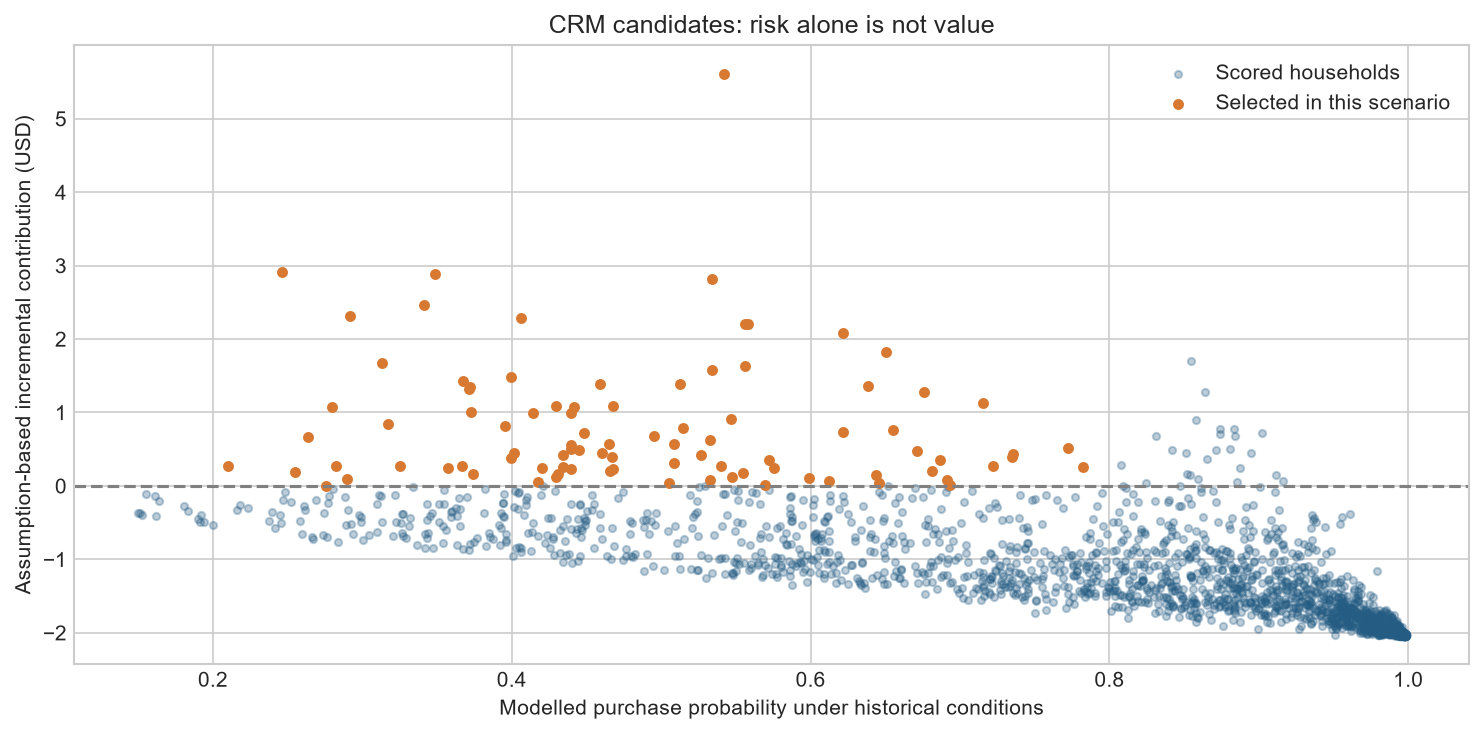

In [10]:
ax.scatter(
    targets.p0_purchase,
    targets.expected_incremental_profit_usd,
    s=18,
    color=ORANGE,
    label="Selected in this scenario",
)
ax.axhline(0, color="grey", linestyle="--")
ax.set(
    xlabel="Modelled purchase probability under historical conditions",
    ylabel="Assumption-based incremental contribution (USD)",
    title="CRM candidates: risk alone is not value",
)
ax.legend(frameon=False)
finish(fig, "06_crm_candidates.png")


## 2. Sensitivity and policy comparison

Re-select the audience for every margin/uplift pair. This is an optimistic assumption-dependent planning exercise, not measured sensitivity of customer response. Alternative policies use the same number of contacts, eligible pool, cost rules and response assumptions. The value ranking winning its own scenario objective is mathematical consistency, not proof of real-world effectiveness.

**Step 9: Build the chart.**

In [11]:
sensitivity = campaign_sensitivity(scored, assumptions)
policies = compare_policies(candidates, len(targets), config["seed"])
display(sensitivity)
display(policies)
profit = sensitivity.pivot(
    index="gross_margin",
    columns="assumed_absolute_uplift",
    values="scenario_incremental_profit_usd",
)
contacts = sensitivity.pivot(
    index="gross_margin",
    columns="assumed_absolute_uplift",
    values="selected_households",
)
fig = Figure(figsize=(12, 4.5))
axes = fig.subplots(1, 2)


,gross_margin,assumed_absolute_uplift,selected_households,worst_case_cost_usd,scenario_incremental_profit_usd
0,0.15,0.00,0,0.00,0.000000
1,0.15,0.02,0,0.00,0.000000
2,0.15,0.05,7,14.35,2.066780
3,0.15,0.10,34,69.70,18.577166
4,0.25,0.00,0,0.00,0.000000
5,0.25,0.02,2,4.10,0.363646
6,0.25,0.05,30,61.50,12.698781
7,0.25,0.10,91,186.55,74.917227
8,0.35,0.00,0,0.00,0.000000
9,0.35,0.02,6,12.30,1.917832


,policy,selected_households,scenario_incremental_profit_usd,worst_case_cost_usd
0,scenario_value,91,74.917227,186.55
1,highest_risk,91,-17.644379,186.55
2,highest_purchase_probability,91,-99.152868,186.55
3,random,91,-67.105796,186.55


In [12]:
display(profit)


assumed_absolute_uplift,0.00,0.02,0.05,0.10
gross_margin,,,,
0.15,0.0,0.000000,2.066780,18.577166
0.25,0.0,0.363646,12.698781,74.917227
0.35,0.0,1.917832,33.916261,164.073160


In [13]:
display(contacts)


assumed_absolute_uplift,0.00,0.02,0.05,0.10
gross_margin,,,,
0.15,0,0,7,34
0.25,0,2,30,91
0.35,0,6,55,121


**Step 10: Build the chart.**

In [14]:
for ax, frame, title, fmt in [
    (axes[0], profit, "Scenario incremental contribution (USD)", ".1f"),
    (axes[1], contacts, "Selected households", ".0f"),
]:
    image = ax.imshow(frame.to_numpy(), aspect="auto", cmap="YlGnBu")
    ax.set_xticks(range(len(frame.columns)), [f"{v:.0%}" for v in frame.columns])
    ax.set_yticks(range(len(frame.index)), [f"{v:.0%}" for v in frame.index])
    ax.set(
        xlabel="Assumed absolute purchase uplift",
        ylabel="Assumed gross margin",
        title=title,
    )


**Step 11: Build the chart.**

In [15]:
for ax, frame, title, fmt in [
    (axes[0], profit, "Scenario incremental contribution (USD)", ".1f"),
    (axes[1], contacts, "Selected households", ".0f"),
]:
    for (r, c), value in np.ndenumerate(frame.to_numpy()):
        ax.text(
            c,
            r,
            format(value, fmt),
            ha="center",
            va="center",
            color=(
                "white" if value > float(frame.to_numpy().max()) * 0.55 else "#17324D"
            ),
            fontsize=11,
        )


**Step 12: Finish and display the chart.**

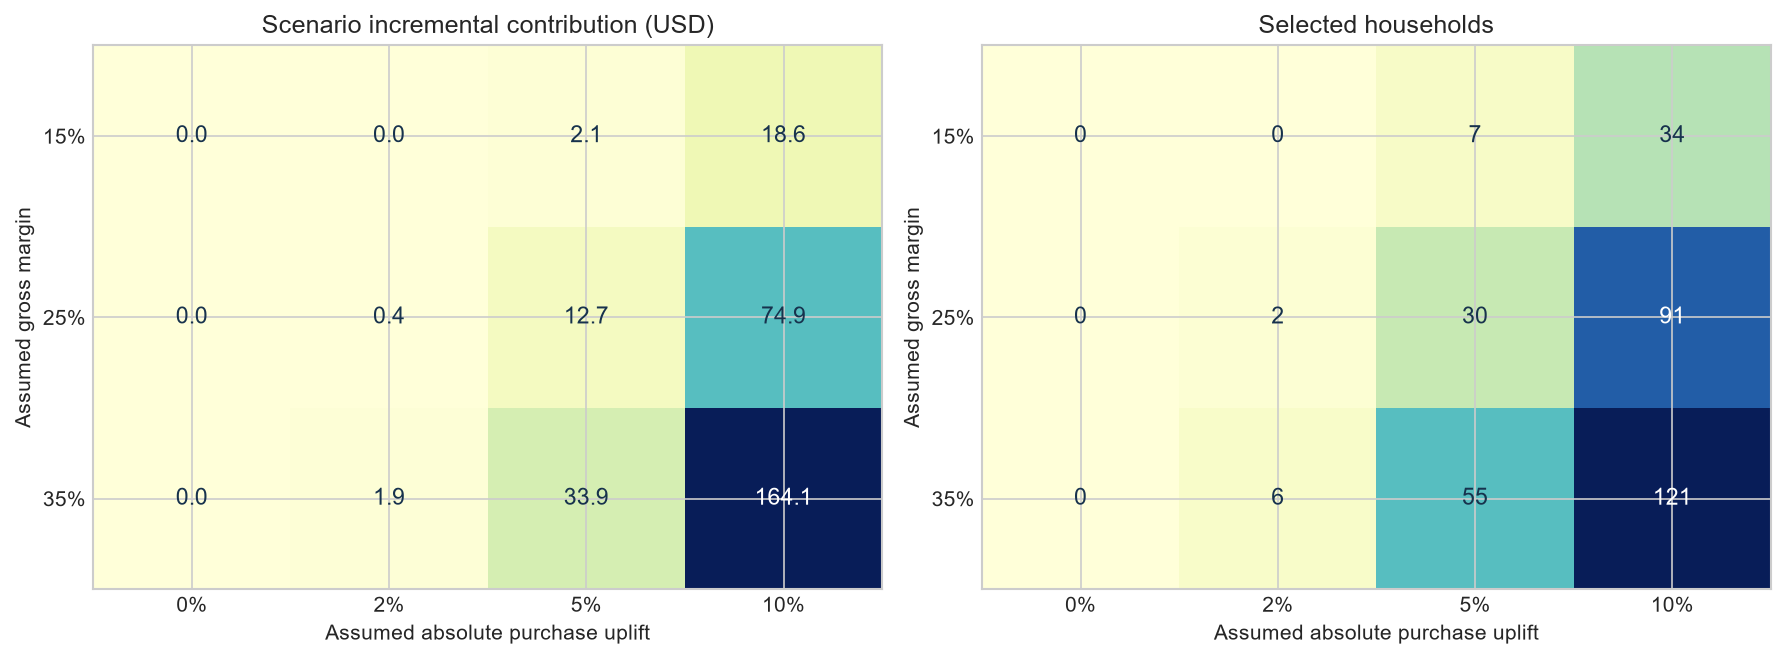

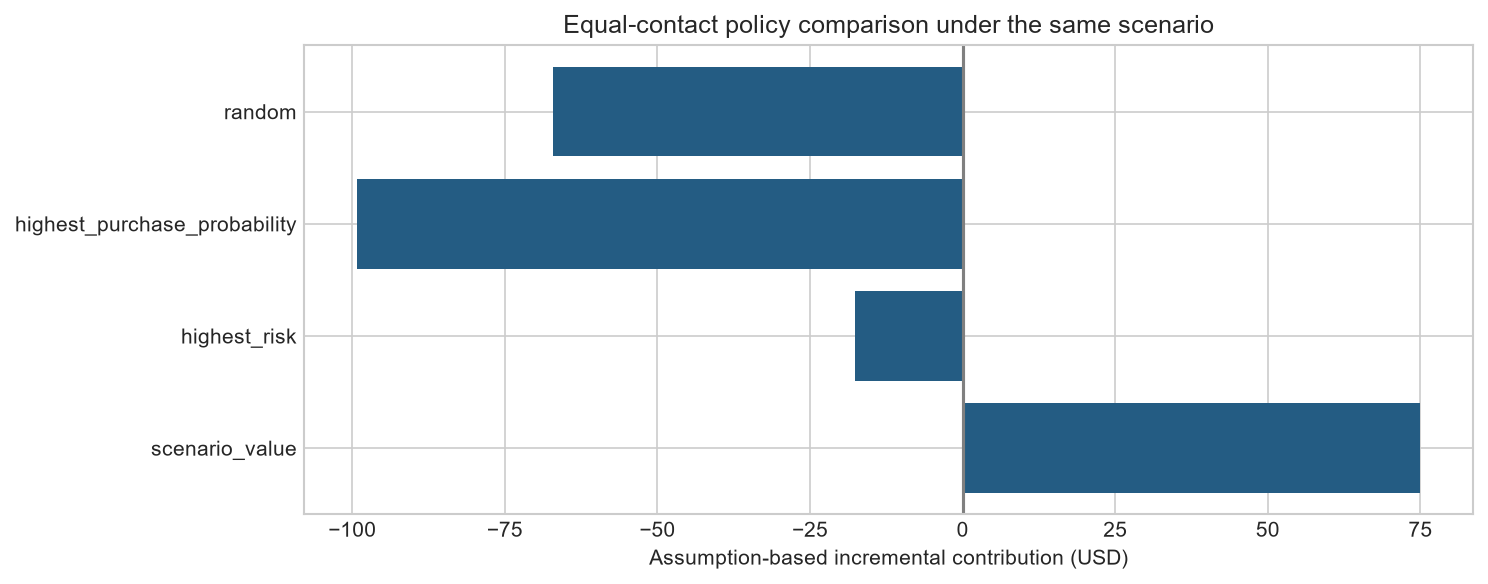

In [16]:
finish(fig, "06_crm_sensitivity.png")
fig = Figure(figsize=(10, 4))
ax = fig.subplots()
ax.barh(policies.policy, policies.scenario_incremental_profit_usd, color=BLUE)
ax.axvline(0, color="grey")
ax.set(
    xlabel="Assumption-based incremental contribution (USD)",
    title="Equal-contact policy comparison under the same scenario",
)
finish(fig, "06_crm_policy_comparison.png")


## 3. Experiment needed before operational use

Randomly assign eligible households within segment/risk strata to offer and no-offer groups before contacting them. Keep household assignment stable. Measure 30-day retailer contribution net of actual offer/contact cost, with purchase rate and sales as secondary outcomes. Analyse intention-to-treat, preserve non-redemptions and prevent offer contamination. Determine sample size from a pilot variance and a business minimum detectable contribution effect; do not invent power from this dataset.

Estimate treatment effects and uncertainty before replacing the assumed uplift. Keep a no-offer holdout in later rollouts and measure cannibalisation among customers who would buy anyway. This project prepares a local target list only; no customer has been contacted and no campaign has been launched.

## 4. Refresh and BI handoff

Run `python scripts/run_pipeline.py` using the project environment to refresh metrics, segments, models, target CSVs and BI aggregates. Household/model files stay under Git-ignored `data/processed/portfolio/`. Power BI and Tableau deliverables are implementation plans, not completed dashboards; see their folders and `docs/dashboard_data_contract.md`.